# Avance Fase 3 · Semana 2
## Núcleo algorítmico, eficiencia y programación orientada a objetos

**Proyecto:** Fallas recurrentes de transmisión en la red de un operador móvil (NOC de WOM, octubre de 2026)
**Curso:** MCDI500 · Programación para la Ciencia de Datos · Magíster en Ciencia de Datos e IA, UNAB
**Integrante:** Edgar Arcia Velásquez (Grupo 6, trabajo individual) · **Docente:** Dr. Omar Salinas Silva

---

## Contexto y objetivo de la Fase 3

La Fase 2 dejó un pipeline que funciona, pero escrito como una secuencia de celdas: para repetirlo
con el exporte de noviembre había que volver a correr el notebook completo y no se podía separar lo
que se aprende de los datos de lo que solo se aplica. Esta fase **no cambia el resultado**; cambia
cómo está construido el código:

1. El código de F2 pasa a módulos en `src/`, con funciones de una sola tarea.
2. Las operaciones que **aprenden algo de los datos** pasan a clases con `ajustar` y `transformar`.
   Las que no aprenden nada siguen siendo funciones.
3. Un `Pipeline` encadena los pasos y ejecuta la Fase 2 completa con una llamada.
4. Se demuestra que el resultado es **idéntico byte a byte** al de la Fase 2.
5. Se miden dos o más implementaciones de las operaciones costosas, en tiempo y memoria, y la
   medición decide cuál queda.
6. Las pruebas de casos normales, límite y excepciones viven en `tests/` y corren con un comando.

| Paso del docente | Sección de este notebook |
|---|---|
| 1. Código en `src/` | 1 y 2 |
| 2. Clases solo donde se aprende de los datos | 3 |
| 3. Pipeline y patrones de diseño justificados | 4 |
| 4. Mismo resultado que F2 | 5 |
| 5. Eficiencia con `timeit` y `tracemalloc` | 6 |
| 6. Pruebas en `tests/` con un comando | 7 |
| 7. Documentación y entrega | 8 y 9 |

Este notebook integra también lo que pide la **Formativa 3** (scripts y mediciones de complejidad): el
código de F2 convertido en scripts de `src/` y las mediciones de la sección 6.

## Configuración del entorno y de las rutas

Misma verificación de las fases anteriores: si el kernel no es el del proyecto, el notebook se
detiene aquí. La diferencia es lo que se importa: en vez de definir funciones en el notebook, se
importan los módulos de `src/`.

In [1]:
import sys
import json
import hashlib
import platform
import subprocess
import tempfile
import unittest
import random
import ast
import inspect
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn

SEMILLA = 42
np.random.seed(SEMILLA)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

print(f"Python {platform.python_version()} · entorno virtual: {'sí' if '.venv' in sys.executable else 'NO'}")
for lib in (np, pd, matplotlib, sklearn):
    print(f"  {lib.__name__:<11} {lib.__version__}")
assert ".venv" in sys.executable, "El kernel no es el del proyecto: Kernel > Change Kernel > Python (mcdi500)"

def localizar_raiz(inicio=None):
    '''Primera carpeta hacia arriba que contiene requirements.txt (la raíz del proyecto).'''
    actual = Path(inicio or Path.cwd()).resolve()
    for carpeta in [actual, *actual.parents]:
        if (carpeta / "requirements.txt").is_file():
            return carpeta
    raise FileNotFoundError("No se encontró la raíz del proyecto (requirements.txt)")

RAIZ = localizar_raiz()
DIR_PROC, DIR_DOCS = RAIZ / "data" / "processed", RAIZ / "docs"
DIR_FIG = DIR_DOCS / "figuras"
DIR_FIG.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(RAIZ))                 # así se importa el paquete src
from src import carga, limpieza, utilidades
from src.transformadores import (Transformador, PasoFijo, UnificadorVariantes, EliminadorCasiVacias,
                                 ImputadorMedianaGrupo, CodificadorNominal, Escalador, ESTRATEGIAS)
from src.pipeline import Pipeline, Bitacora, construir_pipeline, ejecutar
from src.medicion import comparar

def git(*argumentos):
    '''Ejecuta un comando de git en la raíz del proyecto y devuelve su salida.'''
    return subprocess.run(["git", *argumentos], cwd=RAIZ, capture_output=True, text=True).stdout.strip()

print("Raíz del proyecto:", RAIZ.name, "· rama:", git("rev-parse", "--abbrev-ref", "HEAD"), "· commit:", git("rev-parse", "--short", "HEAD"))

Python 3.14.6 · entorno virtual: sí
  numpy       2.5.4
  pandas      3.1.1
  matplotlib  3.11.2
  sklearn     1.9.1
Raíz del proyecto: mcdi500-grupo6 · rama: f3-documentacion · commit: f0dd3c0


## 1. Carga del dataset

**Qué hace.** `carga.cargar_crudo` lee `data/raw` como texto (igual que F2), comprueba que tenga la
forma que registró la Fase 1 en `docs/metadatos_fase1.json` y devuelve la tabla con su huella
SHA-256. Si el archivo no existe o no es el mismo, se detiene con un error propio del proyecto
(`ProyectoError`) en vez de seguir con datos equivocados.

In [2]:
crudo, HUELLA_RAW = carga.cargar_crudo(RAIZ)
meta_f1 = carga.leer_metadatos_f1(RAIZ)
meta_f2 = json.loads((DIR_DOCS / "metadatos_fase2.json").read_text(encoding="utf-8"))

print(f"{crudo.shape[0]:,} filas × {crudo.shape[1]} columnas · igual a la Fase 1".replace(",", "."))
print("SHA-256 de data/raw:", HUELLA_RAW[:16], "...")
assert HUELLA_RAW == meta_f2["entrada"]["sha256"], "data/raw no es el mismo archivo que procesó la Fase 2"
print("[OK] es el mismo archivo que procesó la Fase 2")

try:
    carga.cargar_crudo(RAIZ / "no_existe")
except (FileNotFoundError, utilidades.ProyectoError) as error:
    print("Excepción esperada con una ruta equivocada:", type(error).__name__)

21.542 filas × 49 columnas · igual a la Fase 1
SHA-256 de data/raw: 3951a4f48dbb27cf ...
[OK] es el mismo archivo que procesó la Fase 2
Excepción esperada con una ruta equivocada: FileNotFoundError


## 2. Arquitectura del código en `src/`

**Criterio de división.** Cada módulo responde a una sola pregunta, y las dependencias van en un
solo sentido: `pipeline` usa a `transformadores` y `limpieza`, que usan a `utilidades`; ninguno de
abajo conoce a los de arriba. Así, cambiar la forma de escalar no obliga a tocar la carga ni la
limpieza (bajo acoplamiento), y todo lo que aprende de los datos está en un mismo archivo (alta
cohesión).

La tabla siguiente **se genera leyendo el propio código** con `ast`, para que la documentación no
quede desfasada si el código cambia.

In [3]:
def describir_modulo(ruta):
    '''Resumen de un módulo de src: su propósito (1.ª línea del docstring), funciones, clases y de qué módulos depende.'''
    arbol = ast.parse(ruta.read_text(encoding="utf-8"))
    internos = sorted({alias.name for nodo in ast.walk(arbol) if isinstance(nodo, ast.ImportFrom) and nodo.level == 1
                       for alias in nodo.names if alias.name in MODULOS}
                      | {nodo.module for nodo in ast.walk(arbol) if isinstance(nodo, ast.ImportFrom) and nodo.level == 1 and nodo.module})
    return {"módulo": ruta.name,
            "propósito": (ast.get_docstring(arbol) or "").splitlines()[0],
            "funciones": sum(isinstance(n, ast.FunctionDef) for n in arbol.body),
            "clases": sum(isinstance(n, ast.ClassDef) for n in arbol.body),
            "líneas": len(ruta.read_text(encoding="utf-8").splitlines()),
            "depende de": ", ".join(internos) or "—"}

MODULOS = {"utilidades", "carga", "limpieza", "transformadores", "pipeline", "medicion"}
arquitectura = pd.DataFrame([describir_modulo(RAIZ / "src" / f"{m}.py")
                             for m in ["utilidades", "carga", "limpieza", "transformadores", "pipeline", "medicion"]])
arquitectura

,módulo,propósito,funciones,clases,líneas,depende de
0,utilidades.py,Utilidades del proyecto MCDI500 · Incidencias ...,10,2,209,—
1,carga.py,Carga del conjunto de datos de entrada (data/r...,2,0,32,utilidades
2,limpieza.py,Operaciones del pipeline que NO aprenden de lo...,16,0,227,utilidades
3,transformadores.py,Transformadores: los pasos del pipeline que AP...,1,7,259,utilidades
4,pipeline.py,Pipeline: encadena los pasos y ejecuta toda la...,2,2,145,"carga, limpieza, transformadores"
5,medicion.py,Medición de tiempo y memoria para comparar imp...,3,0,48,—


**Lectura.** `utilidades` y `medicion` no dependen de nadie; `pipeline` es el único que conoce a
todos. Si en la Fase 4 cambia el modelo, se agrega un módulo arriba de `pipeline` sin tocar los de abajo.

## 3. Clases: solo donde se aprende de los datos

**La regla del docente:** si una clase no necesita recordar nada entre llamadas, debe ser una
función. Por eso en `limpieza.py` quedan como funciones la reparación de tildes, los tipos, las
variables derivadas o los ordinales (siempre hacen lo mismo), y en `transformadores.py` quedan como
clases los cinco pasos que **aprenden un parámetro** del conjunto con que se ajustan y lo aplican
después a cualquier otro.

La clase base `Transformador` define el contrato común: `ajustar` controla que existan las columnas,
llama a `aprender` y marca el objeto como ajustado; `transformar` se niega a funcionar sin ajuste y
trabaja sobre una copia. Las clases hijas solo escriben **qué aprenden** y **cómo lo aplican**.

In [4]:
print(inspect.getsource(Transformador))

class Transformador:
    """Clase base: el contrato común de todos los pasos del pipeline. No se usa directamente.

    Define QUÉ métodos tiene un paso y CÓMO se controla su estado; las clases hijas solo
    implementan aprender() y aplicar(), que es lo que cambia de un paso a otro.
    """

    def __init__(self, columnas=()):
        # columnas que el paso necesita en la tabla; acepta un nombre o una lista
        self.columnas = [columnas] if isinstance(columnas, str) else list(columnas)
        self._parametros = {}       # lo que el paso aprende de los datos (estado interno)
        self._ajustado = False      # impide transformar antes de ajustar

    @property
    def nombre(self):
        """Nombre legible del paso: la clase real del objeto y sus columnas."""
        detalle = ", ".join(self.columnas)
        return f"{type(self).__name__}({detalle})" if detalle else type(self).__name__

    @property
    def parametros(self):
        """Copia de lo aprendido: quien la recibe 

La tabla siguiente se arma leyendo las clases de `src/transformadores.py`: de quién hereda cada una,
qué métodos propios escribe y qué hace según su docstring.

In [5]:
def describir_clase(clase):
    '''Fila de la tabla de clases: de quién hereda, qué métodos propios tiene y qué aprende.'''
    propios = [m for m in ("aprender", "aplicar") if m in clase.__dict__]
    return {"clase": clase.__name__, "hereda de": clase.__bases__[0].__name__,
            "sobrescribe": ", ".join(propios),
            "qué hace": inspect.getdoc(clase).splitlines()[0]}

clases = pd.DataFrame([describir_clase(c) for c in Transformador.__subclasses__()])
clases

,clase,hereda de,sobrescribe,qué hace
0,PasoFijo,Transformador,"aprender, aplicar",Envuelve una función que no aprende nada (adap...
1,UnificadorVariantes,Transformador,"aprender, aplicar","Une las escrituras de una misma categoría (""Pe..."
2,EliminadorCasiVacias,Transformador,"aprender, aplicar",Quita las columnas con más de `umbral` % de va...
3,ImputadorMedianaGrupo,Transformador,"aprender, aplicar",Rellena los vacíos de una columna con la media...
4,CodificadorNominal,Transformador,"aprender, aplicar",One-hot de variables nominales: una columna 0/...
5,Escalador,Transformador,"aprender, aplicar",Escala una columna numérica y deja el resultad...


| Principio | Dónde está | Qué evita |
|---|---|---|
| **Herencia** | Las seis clases heredan de `Transformador` y solo escriben `aprender` y `aplicar` | Repetir en cada paso el control de estado, la copia defensiva y la revisión de columnas |
| **Polimorfismo** | `Pipeline.ajustar_transformar` llama al mismo método en los 15 pasos sin preguntar de qué clase es cada uno | Un `if` por tipo de paso; agregar un paso nuevo no cambia el pipeline |
| **Encapsulamiento** | Lo aprendido vive en `_parametros` y `_ajustado`; desde afuera solo se lee una **copia** con la propiedad `parametros` | Que alguien modifique por error una mediana aprendida, o que se transforme sin ajustar |

`PasoFijo` es un **adaptador**: envuelve una función de `limpieza.py` para que el pipeline la recorra
igual que a las clases que aprenden, sin convertir esa función en una clase artificial.

**Ejemplo con datos pequeños.** El imputador aprende la mediana de cada grupo con un conjunto y la
aplica a otro que no vio; el encapsulamiento impide cambiar lo aprendido desde afuera, y transformar
sin ajustar falla con un mensaje claro.

In [6]:
entrenamiento = pd.DataFrame({"duracion_min": [10.0, 30.0, np.nan, 200.0], "tipo": ["Energía", "Energía", "Energía", "Tx Propia"]})
nuevo = pd.DataFrame({"duracion_min": [np.nan, np.nan], "tipo": ["Energía", "Tx Proveedor"]})

imputador = ImputadorMedianaGrupo("duracion_min", ["tipo"], "duracion_imputada").ajustar(entrenamiento)
print("Lo aprendido:", imputador.parametros)
print(imputador.transformar(nuevo))           # Tx Proveedor no estaba: usa la mediana general

copia = imputador.parametros
copia["general"] = 0
print("Después de modificar la copia, el objeto sigue con:", imputador.parametros["general"])

try:
    ImputadorMedianaGrupo("duracion_min", ["tipo"], "x").transformar(nuevo)
except RuntimeError as error:
    print("Excepción esperada:", error)

Lo aprendido: {'por_grupo': tipo
Energía       20.0
Tx Propia    200.0
Name: duracion_min, dtype: float64, 'general': 30.0}
   duracion_min          tipo  duracion_imputada
0           NaN       Energía               20.0
1           NaN  Tx Proveedor               30.0
Después de modificar la copia, el objeto sigue con: 30.0
Excepción esperada: ImputadorMedianaGrupo(duracion_min, tipo): hay que ajustar antes de transformar.


## 4. El pipeline y los patrones de diseño

`construir_pipeline` arma los 15 pasos de la Fase 2 **en el mismo orden** que
`F2_Preprocesamiento.ipynb` (cada línea del código indica la sección de F2 que reemplaza), y
`ejecutar` corre todo: carga, pipeline, armado de los dos conjuntos y tabla de recurrencia.

Se aplican dos patrones, cada uno porque el proyecto lo necesitaba:

| Patrón | Dónde | Problema que resuelve | Qué pasaba sin él |
|---|---|---|---|
| **Observer** | `Bitacora` se suscribe al `Pipeline` y anota filas y columnas antes y después de cada paso | Saber qué hizo cada paso sin llenar los pasos de `print` | En F2 cada celda imprimía su propio control; los pasos quedaban mezclados con el registro |
| **Strategy** | `Escalador` recibe la forma de escalar (`estandar`, `minmax`, `robusta`) como parámetro | F2 usó un escalador distinto por variable; probar otro obligaba a editar el código | Ahora se cambia una palabra y la clase no cambia (ver la comparación más abajo) |

In [7]:
resultado = ejecutar(RAIZ, crudo=crudo)
pipeline = resultado["pipeline"]
print(pipeline)
pipeline.resumen()

Pipeline(15 pasos, ajustado)


,orden,paso,clase,aprende de los datos
0,1,PasoFijo(limpiar_nombres),PasoFijo,no
1,2,PasoFijo(reparar_texto),PasoFijo,no
2,3,PasoFijo(unificar_vacios),PasoFijo,no
3,4,UnificadorVariantes,UnificadorVariantes,sí
4,5,EliminadorCasiVacias,EliminadorCasiVacias,sí
5,6,PasoFijo(convertir_tipos),PasoFijo,no
6,7,"ImputadorMedianaGrupo(duracion_min, tipo_incid...",ImputadorMedianaGrupo,sí
7,8,PasoFijo(derivar_variables),PasoFijo,no
8,9,PasoFijo(codificar_ordinales),PasoFijo,no
9,10,"CodificadorNominal(tipo_incidencia_noc, estado...",CodificadorNominal,sí


**Observer en acción.** La bitácora la llenó el pipeline al pasar por cada paso; ningún paso sabe que existe.

In [8]:
resultado["bitacora"]

,orden,paso,clase,aprende,filas_antes,filas_despues,columnas_antes,columnas_despues
0,1,PasoFijo(limpiar_nombres),PasoFijo,False,21542,21542,49,49
1,2,PasoFijo(reparar_texto),PasoFijo,False,21542,21542,49,49
2,3,PasoFijo(unificar_vacios),PasoFijo,False,21542,21542,49,49
3,4,UnificadorVariantes,UnificadorVariantes,True,21542,21542,49,49
4,5,EliminadorCasiVacias,EliminadorCasiVacias,True,21542,21542,49,29
5,6,PasoFijo(convertir_tipos),PasoFijo,False,21542,21542,29,31
6,7,"ImputadorMedianaGrupo(duracion_min, tipo_incid...",ImputadorMedianaGrupo,True,21542,21542,31,32
7,8,PasoFijo(derivar_variables),PasoFijo,False,21542,21542,32,41
8,9,PasoFijo(codificar_ordinales),PasoFijo,False,21542,21542,41,43
9,10,"CodificadorNominal(tipo_incidencia_noc, estado...",CodificadorNominal,True,21542,21542,43,69


**Strategy en acción.** La misma clase `Escalador`, con tres estrategias, sobre la duración en
logaritmo. F2 eligió la estándar para esta variable porque, después del logaritmo, su forma es
cercana a la normal y no quedan valores extremos que distorsionen la media.

In [9]:
base = resultado["final"][["duracion_log_modelo"]]
estrategias = pd.DataFrame({nombre: Escalador("duracion_log_modelo", "esc", nombre).ajustar_transformar(base)["esc"].describe()
                            for nombre in ESTRATEGIAS}).T.round(3)
estrategias[["mean", "std", "min", "50%", "max"]]

,mean,std,min,50%,max
estandar,0.000,1.000,-2.075,-0.372,3.280
minmax,0.387,0.187,0.000,0.318,1.000
robusta,0.317,0.854,-1.455,0.000,3.119


**Sin fuga de datos.** En F2 todo se ajustó con el conjunto completo, lo que es correcto para un
análisis descriptivo. En la Fase 4 habrá un modelo, y entonces lo aprendido (medianas, categorías,
escalas) debe salir **solo** del conjunto de entrenamiento. El pipeline ya lo permite: se ajusta con
una parte y se aplica a la otra sin volver a aprender.

In [10]:
indices = np.random.default_rng(SEMILLA).permutation(len(crudo))
corte = int(len(crudo) * 0.8)
parte_ajuste, parte_prueba = crudo.iloc[indices[:corte]], crudo.iloc[indices[corte:]]

tubo = construir_pipeline().ajustar(parte_ajuste)
prueba_transformada = tubo.transformar(parte_prueba)

mediana_completo = pipeline.paso(ImputadorMedianaGrupo).parametros["general"]
mediana_ajuste = tubo.paso(ImputadorMedianaGrupo).parametros["general"]
print(f"Ajuste con {len(parte_ajuste):,} filas · se aplica a {len(prueba_transformada):,} filas que no vio".replace(",", "."))
print(f"Mediana general aprendida: {mediana_ajuste:.1f} min (con todo el conjunto: {mediana_completo:.1f} min)")
assert len(prueba_transformada) == len(parte_prueba), "El pipeline perdió o duplicó filas"

Ajuste con 17.233 filas · se aplica a 4.309 filas que no vio
Mediana general aprendida: 72.3 min (con todo el conjunto: 73.7 min)


**Un error que apareció al probar esto.** La primera vez que se ejecutó esta celda, el pipeline se
detuvo en la conversión de tipos: `q_sitios` tenía valores vacíos que no venían en el archivo. La
causa estaba en `UnificadorVariantes`: al aplicar lo aprendido, un valor que no había visto al
ajustar (por ejemplo, una incidencia con 21 sitios que solo estaba en la parte de prueba) quedaba
vacío. Con el conjunto completo no se notaba, porque ajuste y aplicación usan los mismos datos. Se
corrigió para que un valor nuevo se conserve tal cual, y se agregó la prueba
`test_limite_categoria_que_no_se_vio_al_ajustar_se_conserva`. Sin este cambio, la Fase 4 habría
perdido filas en el conjunto de prueba sin dar aviso.

## 5. Verificación: ¿produce el mismo resultado que la Fase 2?

Es la comprobación que más vale: si el pipeline con clases produce exactamente los mismos
archivos que el notebook de la Fase 2, la reorganización no rompió nada. Se comprueba de dos formas:

1. **Huella SHA-256** de cada archivo escrito por F3 contra el de `data/processed` (si cambia un solo
   byte, cambia la huella).
2. **`pd.testing.assert_frame_equal`** sobre las tablas releídas (mismas columnas, tipos y valores).

Los archivos de F3 se escriben en una carpeta temporal: `data/processed` no se toca.

In [11]:
ARCHIVOS = {"limpio": "incidencias_limpio.csv", "modelo": "incidencias_modelo.csv", "recurrencia": "recurrencia_tx_por_sitio.csv"}
filas = []
with tempfile.TemporaryDirectory() as carpeta:
    for clave, nombre in ARCHIVOS.items():
        ruta_f3 = Path(carpeta) / nombre
        resultado[clave].to_csv(ruta_f3, index=False, encoding="utf-8")
        ruta_f2 = DIR_PROC / nombre
        pd.testing.assert_frame_equal(pd.read_csv(ruta_f3, low_memory=False), pd.read_csv(ruta_f2, low_memory=False))
        filas.append({"archivo": nombre, "filas": resultado[clave].shape[0], "columnas": resultado[clave].shape[1],
                      "sha256 F2": utilidades.huella_sha256(ruta_f2)[:12], "sha256 F3": utilidades.huella_sha256(ruta_f3)[:12]})
equivalencia = pd.DataFrame(filas)
equivalencia["idéntico"] = equivalencia["sha256 F2"] == equivalencia["sha256 F3"]
assert equivalencia["idéntico"].all(), "El pipeline con clases no reproduce la Fase 2"
print("[OK] los tres archivos son idénticos byte a byte a los de la Fase 2")
equivalencia

[OK] los tres archivos son idénticos byte a byte a los de la Fase 2


,archivo,filas,columnas,sha256 F2,sha256 F3,idéntico
0,incidencias_limpio.csv,21542,34,4ad2487500af,4ad2487500af,True
1,incidencias_modelo.csv,21542,48,48da91b36f78,48da91b36f78,True
2,recurrencia_tx_por_sitio.csv,559,10,b8d2bf14c28f,b8d2bf14c28f,True


## 6. Eficiencia: medir antes de decidir

**Protocolo** (`src/medicion.py`, según la guía del docente):

- Antes de medir se comprueba que las versiones den **el mismo resultado**; si no, la comparación se detiene.
- Se mide sobre los **datos reales**, con `timeit`, repitiendo y conservando el **menor** tiempo.
- La memoria máxima se mide aparte con `tracemalloc`.
- **Regla fijada antes de medir:** se cambia una versión solo si la nueva es al menos 1,5 veces más
  rápida y no usa más memoria de forma relevante; si no, se conserva la que ya está probada.

Se compararon tres operaciones, elegidas porque son las que más trabajo repiten en el pipeline.

### 6.1 Fusión de intervalos: recursiva (F2) contra iterativa

Para no contar dos veces el tiempo fuera de servicio, F2 une las incidencias que se traslapan en un
mismo sitio con una función **recursiva** (`utilidades.fusionar_intervalos`): fusiona del segundo
intervalo en adelante y decide si el primero se une o queda aparte. La alternativa
(`fusionar_intervalos_iterativo`) ordena una vez y recorre la lista una sola vez.

**Complejidad esperada.** La recursiva vuelve a ordenar y copiar la lista en cada llamada y su
profundidad crece con la cantidad de intervalos, así que su memoria crece como n². En tiempo crece aún
más rápido, cerca de n³, porque cuando dos intervalos se traslapan vuelve a fusionar todo el resto.
Además choca con el límite de recursión de Python (1.000 llamadas por defecto). La iterativa es
O(n log n) en tiempo, por el ordenamiento, y O(n) en memoria.

In [12]:
final = resultado["final"]
foco = limpieza.por_sitio(final[(final["es_tx"] == 1) & (final["afecta_uptime"] == 1)]).dropna(subset=["fecha_cierre"]).copy()
foco["cierre_octubre"] = foco["fecha_cierre"].clip(upper=limpieza.FIN_OCTUBRE)
listas = [list(zip(g["fecha_inicio"], g["cierre_octubre"])) for _, g in foco.groupby("sitio")]
print(f"Datos reales: {len(listas)} sitios, {sum(map(len, listas))} intervalos, máximo {max(map(len, listas))} en un sitio")

def todas_con(fusionar):
    return lambda: [fusionar(lista) for lista in listas]

medicion_a = comparar({"recursiva (F2)": todas_con(utilidades.fusionar_intervalos),
                       "iterativa": todas_con(utilidades.fusionar_intervalos_iterativo)})
medicion_a.round(5)

Datos reales: 557 sitios, 737 intervalos, máximo 11 en un sitio


,tiempo_min_s,memoria_pico_mb,veces_mas_lenta
version,,,
recursiva (F2),0.00035,0.03883,1.4128
iterativa,0.00025,0.04723,1.0000


Con los datos de octubre cada sitio tiene pocos intervalos, así que las dos versiones son rápidas.
La pregunta que decide es **cómo crecen** si un sitio acumula muchas incidencias (un mes peor, o el
análisis de un trimestre). Se mide con listas sintéticas de tamaño creciente:

In [13]:
azar = random.Random(SEMILLA)
crecimiento = []
for n in [10, 50, 100, 200, 400, 700, 900]:
    intervalos = [(a, a + azar.randint(0, 5)) for a in (azar.randint(0, 10 * n) for _ in range(n))]
    tabla = comparar({"recursiva": utilidades.fusionar_intervalos, "iterativa": utilidades.fusionar_intervalos_iterativo},
                     intervalos, repeticiones=3)
    crecimiento.append({"n": n, "recursiva_s": tabla.loc["recursiva", "tiempo_min_s"], "iterativa_s": tabla.loc["iterativa", "tiempo_min_s"],
                        "recursiva_mb": tabla.loc["recursiva", "memoria_pico_mb"], "iterativa_mb": tabla.loc["iterativa", "memoria_pico_mb"]})
crecimiento = pd.DataFrame(crecimiento)
crecimiento["veces"] = (crecimiento["recursiva_s"] / crecimiento["iterativa_s"]).round(0)

try:
    utilidades.fusionar_intervalos([(i, i) for i in range(0, 3000, 2)])
    LIMITE_RECURSION = "sin error"
except RecursionError:
    LIMITE_RECURSION = "RecursionError con 1.500 intervalos"
print("Recursiva con 1.500 intervalos separados:", LIMITE_RECURSION)
print("Iterativa con 1.500 intervalos separados:", len(utilidades.fusionar_intervalos_iterativo([(i, i) for i in range(0, 3000, 2)])), "intervalos, sin error")
crecimiento.round(5)

Recursiva con 1.500 intervalos separados: RecursionError con 1.500 intervalos
Iterativa con 1.500 intervalos separados: 1500 intervalos, sin error


,n,recursiva_s,iterativa_s,recursiva_mb,iterativa_mb,veces
0,10,0.00001,0.00000,0.00089,0.00020,6.0
1,50,0.00022,0.00001,0.02045,0.00069,29.0
2,100,0.00144,0.00002,0.08321,0.00134,95.0
3,200,0.00986,0.00003,0.32314,0.00284,293.0
4,400,0.05258,0.00015,1.26078,0.00540,346.0
5,700,0.30321,0.00014,3.81169,0.00931,2216.0
6,900,0.65764,0.00018,6.27520,0.01266,3672.0


El gráfico muestra las dos curvas: a la izquierda el tiempo, en escala logarítmica porque la diferencia
llega a varios órdenes de magnitud, y a la derecha la memoria máxima. Queda en `docs/figuras/`.

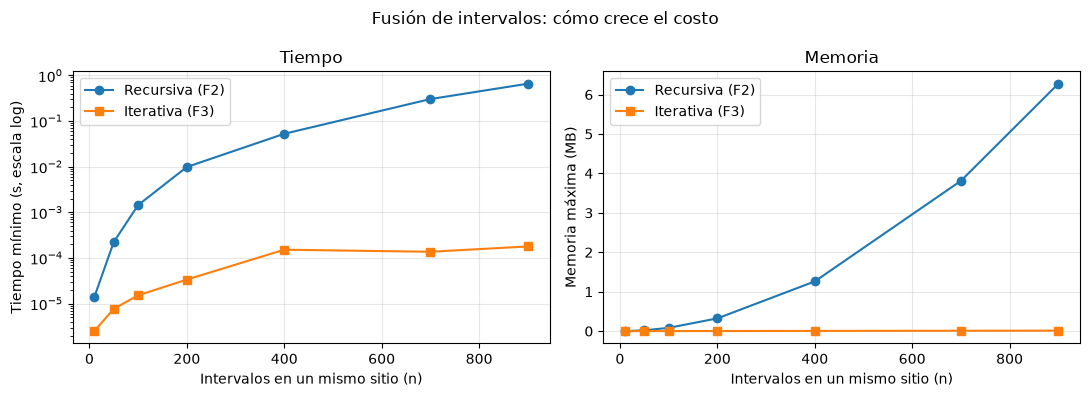

In [14]:
fig, (eje_t, eje_m) = plt.subplots(1, 2, figsize=(11, 4))
for columna, etiqueta, estilo in [("recursiva", "Recursiva (F2)", "o-"), ("iterativa", "Iterativa (F3)", "s-")]:
    eje_t.plot(crecimiento["n"], crecimiento[f"{columna}_s"], estilo, label=etiqueta)
    eje_m.plot(crecimiento["n"], crecimiento[f"{columna}_mb"], estilo, label=etiqueta)
eje_t.set(yscale="log", xlabel="Intervalos en un mismo sitio (n)", ylabel="Tiempo mínimo (s, escala log)", title="Tiempo")
eje_m.set(xlabel="Intervalos en un mismo sitio (n)", ylabel="Memoria máxima (MB)", title="Memoria")
for eje in (eje_t, eje_m):
    eje.grid(alpha=0.3)
    eje.legend()
fig.suptitle("Fusión de intervalos: cómo crece el costo")
fig.tight_layout()
fig.savefig(DIR_FIG / "f3_fusion_crecimiento.png", dpi=150)
plt.show()

**Interpretación.** Las dos versiones dan el mismo resultado (lo comprueba `comparar` y 200 casos al
azar en `tests/`). Con los datos reales la diferencia es pequeña, pero al crecer n la recursiva
se separa rápidamente en tiempo y en memoria, y sobre unos mil intervalos deja de funcionar. La
**decisión**: el pipeline usa la iterativa desde esta fase. La recursiva se conserva en
`utilidades.py` como la versión de F2, documentada y probada, porque el problema sí es recursivo por
naturaleza (unir el primero con la fusión del resto) y sirve de referencia para verificar la otra.

### 6.2 Marcadores de vacío: función por celda (F2) contra vectorizado

F2 reconoce "sin dato" (`NA`, `N/A`, `no aplica`, `-`...) llamando a `utilidades.es_vacio` **una
vez por celda**: más de un millón de llamadas a una función de Python. La alternativa compara cada
columna completa contra el conjunto de marcadores con `isin`, que pandas resuelve en código compilado.

In [15]:
entrada_vacios = limpieza.reparar_texto(limpieza.limpiar_nombres(crudo))
print(f"{entrada_vacios.size:,} celdas".replace(",", "."))
medicion_c = comparar({"es_vacio por celda (F2)": limpieza.unificar_vacios_por_celda, "vectorizado con isin": limpieza.unificar_vacios},
                      entrada_vacios, iguales=lambda a, b: a.equals(b), repeticiones=5)
medicion_c.round(4)

1.055.558 celdas


,tiempo_min_s,memoria_pico_mb,veces_mas_lenta
version,,,
es_vacio por celda (F2),0.4867,16.3338,2.0256
vectorizado con isin,0.2403,16.3278,1.0000


### 6.3 Separar los sitios de una celda: función por celda contra vectorizado

Cuando una incidencia afecta varios sitios, la celda los trae separados por dos o más espacios. F2
usa `separar_sitios` (con validación de celdas vacías) en cada celda; la alternativa usa
`str.split` de pandas sobre la columna completa.

In [16]:
celdas_sitios = final["sitios"]
medicion_b = comparar({"separar_sitios por celda (F2)": lambda: celdas_sitios.map(utilidades.separar_sitios).explode().reset_index(drop=True),
                       "str.split vectorizado": lambda: celdas_sitios.str.strip().str.split(r"\s{2,}", regex=True).explode().reset_index(drop=True)},
                      iguales=lambda a, b: a.equals(b), repeticiones=7)
medicion_b.round(4)

,tiempo_min_s,memoria_pico_mb,veces_mas_lenta
version,,,
separar_sitios por celda (F2),0.0132,3.8678,1.3338
str.split vectorizado,0.0099,3.8680,1.0000


### 6.4 Decisiones

La tabla resume las tres mediciones y aplica la regla fijada al inicio de la sección.

In [17]:
def decidir(tabla, actual, alternativa, cambio_hecho):
    '''Aplica la regla: se cambia solo si la alternativa es al menos 1,5 veces más rápida.'''
    rapidez = tabla.loc[actual, "tiempo_min_s"] / tabla.loc[alternativa, "tiempo_min_s"]
    return {"operación": cambio_hecho, "versión F2": actual, "alternativa": alternativa,
            "tiempo F2 (s)": round(tabla.loc[actual, "tiempo_min_s"], 4), "tiempo alternativa (s)": round(tabla.loc[alternativa, "tiempo_min_s"], 4),
            "veces más rápida": round(rapidez, 2),
            "memoria F2 (MB)": round(tabla.loc[actual, "memoria_pico_mb"], 3), "memoria alternativa (MB)": round(tabla.loc[alternativa, "memoria_pico_mb"], 3),
            "decisión": "se cambia" if rapidez >= 1.5 else "se conserva la de F2"}

n_max = crecimiento.iloc[-1]
fila_octubre = decidir(medicion_a, "recursiva (F2)", "iterativa", "fusión de intervalos (datos de octubre)")
fila_octubre["decisión"] = "diferencia menor a 1 ms: decide el crecimiento (fila siguiente)"
decisiones = pd.DataFrame([
    fila_octubre,
    {"operación": f"fusión de intervalos (n = {int(n_max['n'])})", "versión F2": "recursiva (F2)", "alternativa": "iterativa",
     "tiempo F2 (s)": round(n_max["recursiva_s"], 4), "tiempo alternativa (s)": round(n_max["iterativa_s"], 4),
     "veces más rápida": round(n_max["recursiva_s"] / n_max["iterativa_s"], 0),
     "memoria F2 (MB)": round(n_max["recursiva_mb"], 3), "memoria alternativa (MB)": round(n_max["iterativa_mb"], 3),
     "decisión": "se cambia (además, la recursiva falla sobre ~1.000 intervalos)"},
    decidir(medicion_c, "es_vacio por celda (F2)", "vectorizado con isin", "marcadores de vacío"),
    decidir(medicion_b, "separar_sitios por celda (F2)", "str.split vectorizado", "separar sitios"),
])
decisiones.to_csv(DIR_DOCS / "mediciones_eficiencia_f3.csv", index=False, encoding="utf-8")
decisiones

,operación,versión F2,alternativa,tiempo F2 (s),tiempo alternativa (s),veces más rápida,memoria F2 (MB),memoria alternativa (MB),decisión
0,fusión de intervalos (datos de octubre),recursiva (F2),iterativa,0.0004,0.0002,1.41,0.039,0.047,diferencia menor a 1 ms: decide el crecimiento...
1,fusión de intervalos (n = 900),recursiva (F2),iterativa,0.6576,0.0002,3672.00,6.275,0.013,"se cambia (además, la recursiva falla sobre ~1..."
2,marcadores de vacío,es_vacio por celda (F2),vectorizado con isin,0.4867,0.2403,2.03,16.334,16.328,se cambia
3,separar sitios,separar_sitios por celda (F2),str.split vectorizado,0.0132,0.0099,1.33,3.868,3.868,se conserva la de F2


**Lectura de la tabla.**

- **Fusión de intervalos:** se cambia a la iterativa. Con los datos de octubre las dos tardan menos
  de un milisegundo y la proporción entre ellas varía de una ejecución a otra (entre 1,2 y 2 veces en
  las pruebas), así que esa fila no decide nada. Lo que decide es el crecimiento: con cientos de
  intervalos en un sitio la recursiva es miles de veces más lenta, usa cientos de veces más memoria y
  sobre unos mil intervalos deja de funcionar.
- **Marcadores de vacío:** se cambia a la versión vectorizada, unas 2 veces más rápida con la misma
  memoria. Es la operación que más celdas toca (más de un millón).
- **Separar sitios:** se conserva la de F2. La columna es corta y la versión vectorizada no alcanza
  la regla de 1,5 veces; la de F2 además valida las celdas vacías y ya está probada. Una optimización
  que no mejora de forma clara no justifica cambiar código que funciona.

Los tiempos cambian un poco en cada ejecución, porque dependen de lo que esté haciendo el
computador; por eso se conserva el menor de varias repeticiones y la regla exige una diferencia
amplia antes de cambiar algo.

Los dos cambios ya están en `src/limpieza.py`, y la sección 5 se ejecutó **con ellos**: el resultado
sigue siendo idéntico al de la Fase 2.

## 7. Pruebas: casos normales, límite y excepciones

Las pruebas viven en `tests/test_nucleo.py` y usan `unittest`, que viene con Python (no hay que
instalar nada más). Desde la raíz del proyecto se ejecutan con un solo comando:

```
.venv\Scripts\python.exe -m unittest discover -s tests -v      (Windows)
.venv/bin/python -m unittest discover -s tests -v              (macOS y Linux)
```

Cada prueba usa una tabla pequeña construida a mano, donde el resultado correcto se conoce de
antemano. La última vuelve a ejecutar el pipeline con los datos reales y compara las huellas con F2.
Aquí se ejecutan las mismas pruebas desde el notebook:

In [18]:
def listar_pruebas(suite):
    '''Nombres de todas las pruebas de una suite (las suites se anidan: módulo > clase > prueba).'''
    if isinstance(suite, unittest.TestSuite):
        return [nombre for parte in suite for nombre in listar_pruebas(parte)]
    return [suite.id().split(".")[-1]]

suite = unittest.TestLoader().discover(str(RAIZ / "tests"))
tipos = pd.Series([nombre.split("_")[1] for nombre in listar_pruebas(suite)]).value_counts()   # antes de correr: run() vacía la suite
informe_pruebas = unittest.TextTestRunner(stream=sys.stdout, verbosity=2).run(suite)
print("\nPruebas por escenario:", tipos.to_dict())
assert informe_pruebas.wasSuccessful(), "Hay pruebas que fallan"

test_normal_mismos_archivos_que_la_fase_2 (test_nucleo.PruebaEquivalenciaConFase2.test_normal_mismos_archivos_que_la_fase_2) ... ok
test_excepcion_estrategia_desconocida (test_nucleo.PruebasCodificadorYEscalador.test_excepcion_estrategia_desconocida) ... ok
test_limite_frecuencia_minima_agrupa_las_raras (test_nucleo.PruebasCodificadorYEscalador.test_limite_frecuencia_minima_agrupa_las_raras) ... ok
test_limite_minmax_entre_cero_y_uno (test_nucleo.PruebasCodificadorYEscalador.test_limite_minmax_entre_cero_y_uno) ... ok
test_normal_escala_estandar_media_cero (test_nucleo.PruebasCodificadorYEscalador.test_normal_escala_estandar_media_cero) ... ok
test_normal_one_hot_suma_uno_y_vacio_es_sin_dato (test_nucleo.PruebasCodificadorYEscalador.test_normal_one_hot_suma_uno_y_vacio_es_sin_dato) ... ok
test_limite_grupo_sin_datos_usa_la_mediana_general (test_nucleo.PruebasImputador.test_limite_grupo_sin_datos_usa_la_mediana_general) ... ok
test_limite_sin_vacios_no_cambia_nada (test_nucleo.PruebasIm

## 8. Resultado y contrato con la Fase 4

**Qué queda listo.** Los tres archivos de F2 en `data/processed` no cambian: ahora los produce
código reutilizable. Se agregan dos archivos para la Fase 4 y el registro de esta fase.

### El contrato entre fases

| Artefacto | Qué contiene | Para qué lo usa la Fase 4 |
|---|---|---|
| `incidencias_limpio.csv` | Las 21.542 incidencias limpias y legibles | Explorar y visualizar con nombres reales de las categorías |
| `incidencias_modelo.csv` | La misma tabla en formato numérico | Si se ajusta un modelo |
| `recurrencia_tx_por_sitio.csv` | Una fila por sitio con sus fallas y minutos fuera de servicio | Responder la pregunta del proyecto |
| `diccionario_f3.csv` | Cada columna de los tres archivos, con su tipo, su % de vacíos y el paso que la crea | Saber qué significa cada variable |
| `parametros_f3.csv` | Lo que aprendió cada paso del pipeline | Reproducir o auditar el resultado |

**Por qué no hay archivos de entrenamiento y prueba.** El proyecto es descriptivo: la pregunta se
responde con la recurrencia de todo octubre, y partir los datos dejaría sitios con la mitad de sus
fallas. Si la Fase 4 ajusta un modelo, el pipeline ya permite ajustar con una parte y aplicar a la
otra (sección 4).

**Lo que la Fase 4 no debe hacer:** volver a imputar, codificar o escalar los archivos de
`data/processed`, porque ya están transformados. Si necesita una transformación nueva, se agrega
como un paso más en `src/pipeline.py`.

El diccionario se arma con un **segundo observador** del pipeline, que anota qué paso crea cada
columna. Es la ventaja del patrón Observer: se agrega una función nueva sin tocar el `Pipeline` ni
los pasos.

In [19]:
class OrigenColumnas:
    '''Observador: anota qué paso del pipeline crea cada columna.'''
    def __init__(self):
        self.origen = {}

    def notificar(self, orden, paso, antes, despues):
        if orden == 1:                                    # el primer paso solo normaliza los nombres del archivo
            nuevas, etiqueta = despues.columns, "data/raw (nombre normalizado)"
        else:
            nuevas, etiqueta = despues.columns.difference(antes.columns), f"{orden}. {paso.nombre}"
        for columna in nuevas:
            self.origen[columna] = etiqueta

origen = OrigenColumnas()
construir_pipeline([origen]).ajustar_transformar(crudo)  # mismo pipeline, ahora con este observador

filas = []
for clave, nombre in ARCHIVOS.items():
    tabla = resultado[clave]
    for columna in tabla.columns:
        filas.append({"archivo": nombre, "columna": columna, "tipo": str(tabla[columna].dtype),
                      "pct_vacio": round(tabla[columna].isna().mean() * 100, 1),
                      "origen": origen.origen.get(columna, "tabla_recurrencia" if clave == "recurrencia" else "armar_conjuntos")})
diccionario_f3 = pd.DataFrame(filas)
diccionario_f3.to_csv(DIR_PROC / "diccionario_f3.csv", index=False, encoding="utf-8")
print(diccionario_f3.groupby("archivo").size().to_string())
diccionario_f3[diccionario_f3["archivo"] == "incidencias_modelo.csv"].head(12)

archivo
incidencias_limpio.csv          34
incidencias_modelo.csv          48
recurrencia_tx_por_sitio.csv    10


,archivo,columna,tipo,pct_vacio,origen
34,incidencias_modelo.csv,tt,str,0.0,data/raw (nombre normalizado)
35,incidencias_modelo.csv,criticidad_ord,float64,0.0,9. PasoFijo(codificar_ordinales)
36,incidencias_modelo.csv,es_extendida,float64,0.0,8. PasoFijo(derivar_variables)
37,incidencias_modelo.csv,impacto_ord,float64,0.0,9. PasoFijo(codificar_ordinales)
38,incidencias_modelo.csv,afecta_uptime,float64,0.0,8. PasoFijo(derivar_variables)
39,incidencias_modelo.csv,es_tx,float64,0.0,8. PasoFijo(derivar_variables)
40,incidencias_modelo.csv,duracion_faltante,float64,0.0,6. PasoFijo(convertir_tipos)
41,incidencias_modelo.csv,cierre_invalido,float64,0.0,6. PasoFijo(convertir_tipos)
42,incidencias_modelo.csv,gestionable,float64,0.0,data/raw (nombre normalizado)
43,incidencias_modelo.csv,gestor_uptime,float64,0.0,data/raw (nombre normalizado)


El segundo archivo del contrato resume lo que aprendió cada paso: las medianas, las columnas que se
eliminaron, las categorías del one-hot y los parámetros de cada escalador.

In [20]:
def resumir_parametros(paso):
    '''Texto corto con lo que aprendió un paso (las tablas aprendidas se resumen por su tamaño).'''
    if isinstance(paso, PasoFijo):
        return "no aprende: función fija"
    if isinstance(paso, UnificadorVariantes):
        formas = paso.parametros["formas"]
        return f"{len(formas)} columnas categóricas, {sum(len(f) for f in formas.values())} formas aprendidas"
    if isinstance(paso, EliminadorCasiVacias):
        return "elimina: " + ", ".join(paso.parametros["casi_vacias"] + paso.parametros["fuera_de_alcance"])
    if isinstance(paso, ImputadorMedianaGrupo):
        aprendido = paso.parametros
        return f"medianas de {len(aprendido['por_grupo'])} grupos; general {aprendido['general']:.1f} min"
    if isinstance(paso, CodificadorNominal):
        return f"{len(paso.columnas_nuevas)} columnas: " + ", ".join(paso.columnas_nuevas)
    if isinstance(paso, Escalador):
        motor = paso.parametros["motor"]
        valores = {atributo: round(float(getattr(motor, atributo)[0]), 4)
                   for atributo in ("mean_", "scale_", "data_min_", "data_max_", "center_") if hasattr(motor, atributo)}
        return f"{type(motor).__name__} {valores}"
    return str(paso.parametros)

parametros_f3 = pd.DataFrame([{"orden": i, "paso": paso.nombre, "clase": type(paso).__name__, "aprendido": resumir_parametros(paso)}
                              for i, paso in enumerate(pipeline.pasos, start=1)])
parametros_f3.to_csv(DIR_PROC / "parametros_f3.csv", index=False, encoding="utf-8")
with pd.option_context("display.max_colwidth", 90):
    display(parametros_f3)

,orden,paso,clase,aprendido
0,1,PasoFijo(limpiar_nombres),PasoFijo,no aprende: función fija
1,2,PasoFijo(reparar_texto),PasoFijo,no aprende: función fija
2,3,PasoFijo(unificar_vacios),PasoFijo,no aprende: función fija
3,4,UnificadorVariantes,UnificadorVariantes,"37 columnas categóricas, 1167 formas aprendidas"
4,5,EliminadorCasiVacias,EliminadorCasiVacias,"elimina: tramo_afectado, horario_posible_degradacion, etr, descripcion_tx_1, proveedor..."
5,6,PasoFijo(convertir_tipos),PasoFijo,no aprende: función fija
6,7,"ImputadorMedianaGrupo(duracion_min, tipo_incidencia_noc, criticidad)",ImputadorMedianaGrupo,medianas de 50 grupos; general 73.7 min
7,8,PasoFijo(derivar_variables),PasoFijo,no aprende: función fija
8,9,PasoFijo(codificar_ordinales),PasoFijo,no aprende: función fija
9,10,"CodificadorNominal(tipo_incidencia_noc, estado, region_principal)",CodificadorNominal,"26 columnas: tipo_incidencia_noc_energia, tipo_incidencia_noc_incidencia_automatica, t..."


Por último se escribe el registro de la fase en `docs/metadatos_fase3.json` y se comprueba que
`data/raw` siga igual que al inicio.

In [21]:
meta_f3 = {
    "fase": "F3", "generado": datetime.now().isoformat(timespec="seconds"), "commit_base": git("rev-parse", "--short", "HEAD"),
    "entrada": {"archivo": meta_f1["dataset"]["archivo"], "sha256": HUELLA_RAW, "filas": int(crudo.shape[0])},
    "salidas_identicas_a_f2": {fila["archivo"]: bool(fila["idéntico"]) for _, fila in equivalencia.iterrows()},
    "pipeline": pipeline.resumen().to_dict("records"),
    "patrones": {"Observer": "Bitacora suscrita al Pipeline", "Strategy": "Escalador con estrategia de escalamiento",
                 "Adaptador": "PasoFijo envuelve las funciones sin estado"},
    "eficiencia": decisiones.to_dict("records"),
    "limite_recursion": LIMITE_RECURSION,
    "duraciones_imputadas": int(final["duracion_faltante"].sum()),
    "pruebas": {"ejecutadas": informe_pruebas.testsRun, "fallas": len(informe_pruebas.failures), "errores": len(informe_pruebas.errors),
                "por_escenario": {k: int(v) for k, v in tipos.items()}},
    "entregables_fase4": ["data/processed/" + n for n in [*ARCHIVOS.values(), "diccionario_f3.csv", "parametros_f3.csv"]],
    "como_usar": "from src.pipeline import construir_pipeline; tubo = construir_pipeline().ajustar(entrenamiento); tubo.transformar(prueba)",
}
(DIR_DOCS / "metadatos_fase3.json").write_text(json.dumps(meta_f3, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
assert utilidades.huella_sha256(RAIZ / meta_f1["dataset"]["archivo"]) == HUELLA_RAW, "data/raw cambió"
for ruta in [DIR_PROC / "diccionario_f3.csv", DIR_PROC / "parametros_f3.csv",
             DIR_DOCS / "metadatos_fase3.json", DIR_DOCS / "mediciones_eficiencia_f3.csv", DIR_FIG / "f3_fusion_crecimiento.png"]:
    print(f"{ruta.relative_to(RAIZ).as_posix():<40} {ruta.stat().st_size / 1e3:7.1f} kB")
print("[OK] data/raw no cambió")
print("Incidencias sin duración (imputadas solo para el conjunto de modelos):", meta_f3["duraciones_imputadas"])

data/processed/diccionario_f3.csv            8.6 kB
data/processed/parametros_f3.csv             2.5 kB
docs/metadatos_fase3.json                    5.3 kB
docs/mediciones_eficiencia_f3.csv            0.7 kB
docs/figuras/f3_fusion_crecimiento.png      84.6 kB
[OK] data/raw no cambió
Incidencias sin duración (imputadas solo para el conjunto de modelos): 5320


## 9. Conclusiones y proyección a la Fase 4

**Qué cambió desde la Fase 2.**

| Antes (F2) | Ahora (F3) |
|---|---|
| Funciones definidas dentro del notebook | Seis módulos en `src/`, cada uno con una responsabilidad |
| Lo aprendido (medianas, categorías, escalas) quedaba en variables sueltas | Cinco clases que lo guardan protegido y lo aplican a cualquier conjunto |
| Repetir el análisis exigía correr el notebook completo | `ejecutar(RAIZ)` repite la Fase 2 con una llamada |
| Pruebas dentro del notebook | `tests/` con casos normales, límite y excepciones, y un comando |
| Fusión recursiva y marcadores celda a celda | Versiones medidas y elegidas por su costo, con el mismo resultado |

**Correcciones de la retroalimentación de la Sumativa 1 que se integraron.** Repositorio privado;
sitios identificados con código y texto libre omitido, también en el historial; `requirements.txt`
solo con las librerías del proyecto, probado en Linux, macOS y Windows; trabajo en ramas por
componente con commits en días distintos.

**Limitación que se declara.** 5.320 incidencias no tienen una duración válida: 5.318 venían vacías (seguían abiertas al exportar) y 2 eran negativas.
El `ImputadorMedianaGrupo` les asigna la mediana de su tipo y criticidad, pero ese valor se usa
**solo** en el conjunto para modelos (`duracion_log_esc`). La tabla de recurrencia, que responde la
pregunta del proyecto, cuenta los minutos con las fechas reales y deja las abiertas en una columna
aparte: ahí no hay valores imputados.

**Para la Fase 4.**

- Separar entrenamiento y prueba **antes** de ajustar el pipeline (la sección 4 muestra que ya funciona).
- Usar la tabla de recurrencia para priorizar los sitios y el tipo de enlace que más tiempo fuera de
  servicio acumulan.
- Si se analiza un trimestre, la fusión iterativa ya soporta sitios con miles de incidencias.

## Verificación antes de entregar

- [x] *Kernel → Restart Kernel and Run All Cells* sin errores y con numeración continua.
- [x] La sección 5 muestra los tres archivos idénticos a la Fase 2.
- [x] La sección 7 muestra todas las pruebas en OK.
- [x] La sección 8 deja `diccionario_f3.csv` y `parametros_f3.csv` en `data/processed`.
- [x] Las cifras del informe son las de las tablas de las secciones 5, 6 y 7.
- [x] Salidas guardadas (Ctrl+S) **antes** del commit.